# Esercizio 1) Caso con zero semplice

Definire la funzione $f(x)=(4x-7)/(x-2)$  e calcolarne la derivata. 
Poi:
- calcolare (a mano) lo zero `x_star`;
- plottare $f(x)$ nell’intervallo $[1, 1.9]$  e individuare graficamente lo zero;
- implementare il metodo di bisezione e i metodi di Newton e delle secanti in modo che stampino ad ogni iterazione il punto $x_k$ calcolato e il valore della funzione in quel punto.

Per il metodo di bisezione:
- lanciare il metodo di bisezione per la ricerca dello zero tra `a=1` e `b=1.9`;
- memorizzare punti medi e ampiezze degli intervalli ad ogni iterazione;
- provare le tolleranze `tol` pari a $10^{-4}, 10^{-8}, 10^{-12}$;
- confrontare le approssimazioni iterative con la stima teorica `x_star`.

Per il metodo di Newton:
- lanciare il metodo di Newton con $x_0 = 1.9$, poi testare $x_0 = {1, 1.5, 1.6}$;
- provare le tolleranze `tol` pari a $10^{-4}, 10^{-8}, 10^{-12}$;
- confrontare le approssimazioni iterative con la stima teorica `x_star` e plottare come si riduce l'errore di approssimazione.

Per il metodo delle secanti:
- implementare e lanciare il metodo delle secanti con $x_0 = 1$ e $x_1 = 1.9$;
- provare diversi input per $x_0$ e $X_1$, tipo $x_0 = 1$ e $x_1 = 1.8$;
- provare le tolleranze `tol` pari a $10^{-4}, 10^{-8}, 10^{-12}$;
- confrontare le approssimazioni iterative con la stima teorica `x_star` e plottare come si riduce l'errore di approssimazione.

NB:
* Che tipi di errori si ottengono? A cosa sono dovuti?
* Fra i metodi testati, quale metodo converge più rapidamente a parità di tolleranza? Quali informazioni richiede in cambio?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
eps = np.finfo(float).eps

#### Funzioni da usare per risolvere il problema

In [51]:
def bisezione(f, a, b, tol=1e-12, max_iter=100):

    fa = f(a)
    fb = f(b)
    iterati = []

    # Controllo degli estremi
    if fa * fb > 0:
        raise ValueError("La funzione deve cambiare segno in [a, b].")
    
    if fa == 0:
        return a, 0, iterati

    if fb == 0:
        return b, 0, iterati

    
    for k in range(1, max_iter + 1):

        # Punto medio e valore della funzione
        m = (a + b) / 2
        fm = f(m)

        # Memorizzo l'approssimazione corrente
        iterati.append(m)

        # Criterio di arresto
        if abs(b - a) / 2 <= tol + eps * min(abs(a), abs(b))   or fm == 0:
            print("Raggiunto il criterio di arresto.")
            return m, k, iterati

        # Seleziono il sottointervallo con cambio di segno, per la prossima iterazione
        if fa * fm < 0:
            b = m
        else:
            a = m
            fa = fm

    print("Raggiunto il numero massimo di iterazioni.")
    return m, k, iterati

In [ ]:
def newton(f, df, x0, tol_x=1e-12, tol_f=1e-14, max_iter=100):

    x = x0         
    iterati = [x]

    print(f"k = 0, x = {x:.15f}, f(x) = {f(x):.3e}")

    # Controllo del punto iniziale
    if abs(f(x)) <= tol_f:
        return x, 0, iterati
    
    for k in range(1, max_iter + 1):

        fx = f(x)
        dfx = df(x)

        # Controllo della derivata
        if dfx == 0:
            raise ValueError("Derivata nulla: impossibile proseguire.")

        # Nuova approssimazione
        x_nuovo = x - fx / dfx
        print(f"k = {k:2d}, x = {x_nuovo:.15f}, f(x) = {f(x_nuovo):.3e}")
        iterati.append(x_nuovo)

        # Incremento e residuo
        incremento = abs(x_nuovo - x)
        residuo = abs(f(x_nuovo))       # sarebbe: abs(f(x_nuovo) - f(x_star)) = abs(f(x_nuovo) - 0)

        # Criteri di arresto
        if incremento <= tol_x + eps * min(abs(x_nuovo), abs(x)) or residuo <= tol_f:
            print("Raggiunto un criterio di arresto.")
            return x_nuovo, k, iterati

        # Aggiornamento per la prossima iterazione
        x = x_nuovo


    print("Raggiunto il numero massimo di iterazioni.")
    return x, max_iter, iterati

In [ ]:
def secanti(f, x0, x1, tol_x=1e-12, tol_f=1e-14, max_iter=100):

    x_prec = float(x0)
    x = float(x1)

    iterati = [x_prec, x]

    f_prec = f(x_prec)
    fx = f(x)

    print(f"k = -1, x = {x_prec:.15f}, f(x) = {f_prec:.3e}")
    print(f"k = 0, x = {x:.15f}, f(x) = {fx:.3e}")

    # Controllo dei punti iniziali
    if abs(f_prec) <= tol_f:
        return x_prec, 0, [x_prec]

    if abs(fx) <= tol_f:
        return x, 0, iterati

    for k in range(1, max_iter + 1):

        # Controllo del denominatore
        denominatore = fx - f_prec

        if denominatore == 0:
            raise ValueError("Denominatore nullo: impossibile proseguire.")

        # Nuova approssimazione
        x_nuovo = x - fx * (x - x_prec) / denominatore
        f_nuovo = f(x_nuovo)
        iterati.append(x_nuovo)
        print(f"k = {k:2d}, x = {x_nuovo:.15f}, f(x) = {f_nuovo:.3e}")

        # Incremento e residuo
        incremento = abs(x_nuovo - x)
        residuo = abs(f_nuovo)

        # Criteri di arresto
        if incremento <= tol_x  + eps * min(abs(x_nuovo), abs(x)) or residuo <= tol_f:
            print("Raggiunto un criterio di arresto.")
            return x_nuovo, k, iterati

        # Aggiorno i due punti e i valori della funzione
        x_prec = x
        f_prec = fx

        x = x_nuovo
        fx = f_nuovo

    print("Raggiunto il numero massimo di iterazioni.")
    return x, max_iter, iterati

####  Definizione del problema

In [52]:
def f(x):
    return (4*x-7)/(x-2)

x_star = 7/4
print(f"f(x_star) = {f(x_star)}")

f(x_star) = -0.0


In [5]:
print(f"f2) = {f(2)}")

ZeroDivisionError: division by zero

Devo calcolare $df(x) = f'(x)$ con la regola di derivazione del quoziente

$$
f(x)' = \left[ \frac{f_N(x)}{f_D(x)} \right]' = \frac{f_N'(x) \cdot f_D(x) - f_N(x) \cdot f_D'(x)}{[f_D(x)]^2},
$$

quindi:

$$
f'(x) = \frac{4(x-2) - (4x-7)}{(x-2)^2} = \frac{-1}{(x-2)^2}
$$

In [ ]:
def df(x):
    return -1 / (x - 2)**2

#### Visualizzazione

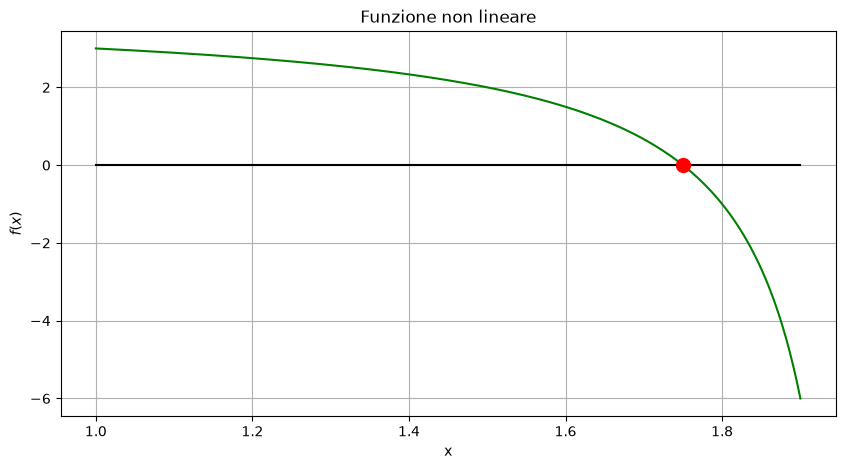

In [32]:
a = 1
b = 1.9

x = np.linspace(a, b, 200)
y = f(x)
yzeros = np.zeros_like(y)

plt.figure(figsize=(10, 5))
plt.plot(x,y, "-", color = 'green')
plt.plot(x,yzeros, "-", color = 'black')
plt.plot(x_star, f(x_star), "o", color = 'red', markersize=10 )
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione non lineare")
# plt.legend ...
plt.grid(True)

#### Risoluzione con bisezione

In [ ]:
x_bisez, n_iter_bisez, iterati_bisez = bisezione(f, a, b, tol=1e-12)

print("Zero analitico:", x_star)
print("Zero approssimato:", x_bisez)
print("Numero di iterazioni:", n_iter_bisez)

Raggiunto il criterio di arresto.
Zero analitico: 1.75
Zero approssimato: 1.7499999999997269
Numero di iterazioni: 40


In [ ]:
print(type(iterati_bisez))
iterati_bisez = np.array(iterati_bisez)

<class 'list'>


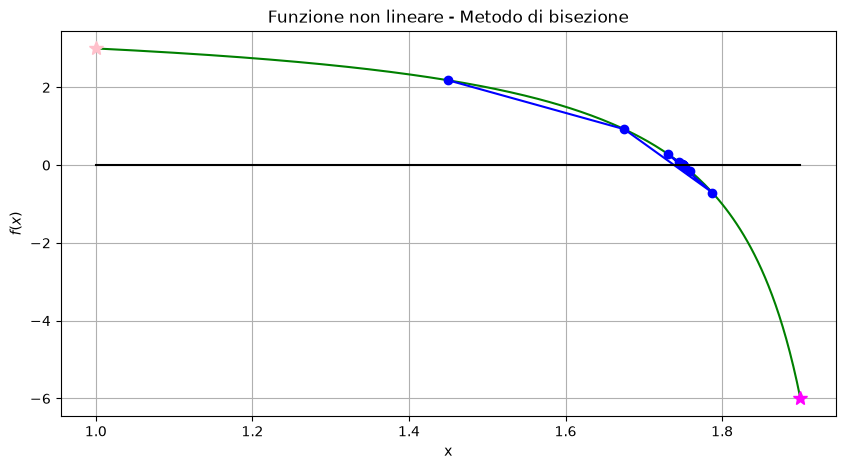

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(x, y, "-", color = 'green')
plt.plot(a, f(a), "*", color = 'pink', markersize = 10)
plt.plot(b, f(b), "*", color = 'magenta', markersize = 10)
plt.plot(iterati_bisez, f(iterati_bisez), "o-", color = 'blue')
# plt.plot(x_star, f(x_star), "o", color = 'red' )
plt.plot(x,yzeros, "-", color = 'black')
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione non lineare - Metodo di bisezione")
# plt.legend ...
plt.grid(True)

In [ ]:
for k in range(1, n_iter_bisez+1): 
    print( f"Al passo k={k}, errore={np.abs(x_star - iterati_bisez[k-1]):.3e}" )

Al passo k=1, errore=3.000e-01
Al passo k=2, errore=7.500e-02
Al passo k=3, errore=3.750e-02
Al passo k=4, errore=1.875e-02
Al passo k=5, errore=9.375e-03
Al passo k=6, errore=4.688e-03
Al passo k=7, errore=2.344e-03
Al passo k=8, errore=1.172e-03
Al passo k=9, errore=5.859e-04
Al passo k=10, errore=2.930e-04
Al passo k=11, errore=1.465e-04
Al passo k=12, errore=7.324e-05
Al passo k=13, errore=3.662e-05
Al passo k=14, errore=1.831e-05
Al passo k=15, errore=9.155e-06
Al passo k=16, errore=4.578e-06
Al passo k=17, errore=2.289e-06
Al passo k=18, errore=1.144e-06
Al passo k=19, errore=5.722e-07
Al passo k=20, errore=2.861e-07
Al passo k=21, errore=1.431e-07
Al passo k=22, errore=7.153e-08
Al passo k=23, errore=3.576e-08
Al passo k=24, errore=1.788e-08
Al passo k=25, errore=8.941e-09
Al passo k=26, errore=4.470e-09
Al passo k=27, errore=2.235e-09
Al passo k=28, errore=1.118e-09
Al passo k=29, errore=5.588e-10
Al passo k=30, errore=2.794e-10
Al passo k=31, errore=1.397e-10
Al passo k=32, er

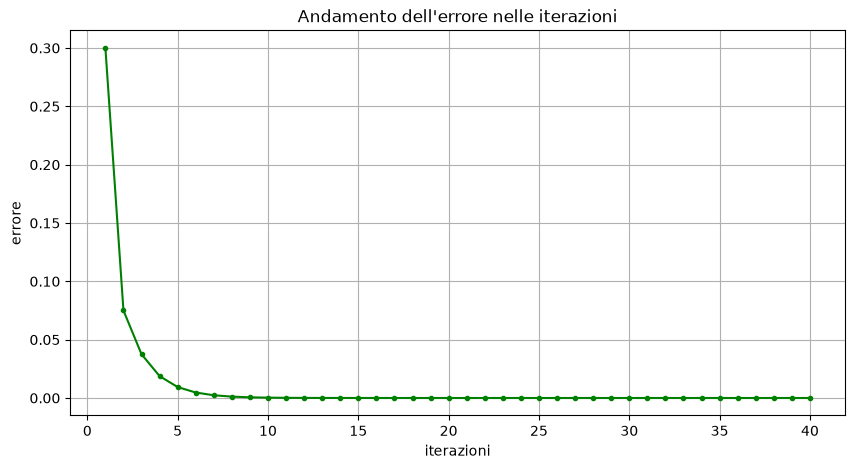

In [ ]:
errori_bisez = np.abs(iterati_bisez-x_star)
iterazioni_bisez = np.arange(1,n_iter_bisez+1)

plt.figure(figsize=(10, 5))
plt.plot(iterazioni_bisez, errori_bisez, ".-", color = 'green')
#plt.semilogy(iterazioni, errori, ".-", color = 'green')
plt.xlabel("iterazioni")
plt.ylabel(r"errore")
plt.title("Andamento dell'errore nelle iterazioni")
plt.grid(True)


In [ ]:
# TO DO: calcolare le ampiezze degli intervalli ad ogni iterazione

#### Risoluzione con Newton

In [ ]:
x0 = 1.9
x_newton, n_iter_newton, iterati_newton = newton(f, df, x0)

print("Zero analitico:", x_star)
print("Zero approssimato:", x_newton)
print("Numero di iterazioni:", n_iter_newton)

In [ ]:
print(type(iterati_newton))
iterati_newton = np.array(iterati_newton)
print(iterati_newton)

In [ ]:
for k in range(0, n_iter_newton+1): 
    print( f"Al passo k={k}, errore={np.abs(x_star - iterati_newton[k]):.3e}" )

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(x, y, "-", color = 'green')
plt.plot(x0, f(x0), "*", color = 'magenta', markersize = 15)
plt.plot(iterati_newton, f(iterati_newton), "o-", color = 'blue')
# plt.plot(x_star, f(x_star), "o", color = 'red' )
plt.plot(x,yzeros, "-", color = 'black')
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione non lineare - Metodo di Newton")
# plt.legend ...
plt.grid(True)

In [ ]:
errori_newton = np.abs(iterati_newton-x_star)
iterazioni_newton = np.arange(0,n_iter_newton+1) # abbiamo anche x0

plt.figure(figsize=(10, 5))
plt.plot(iterazioni_newton, errori_newton, ".-", color = 'green')
# plt.semilogy(iterazioni, errori, ".-", color = 'green')
plt.xlabel("iterazioni")
plt.ylabel(r"errore")
plt.title("Andamento dell'errore nelle iterazioni")
plt.grid(True)

#### Risoluzione col metodo delle secanti

In [ ]:
x0 = 1
x1 = 1.8
x_sec, n_iter_sec, iterati_sec = secanti(f, x0, x1)

print("Zero analitico:", x_star)
print("Zero approssimato:", x_sec)
print("Numero di iterazioni:", n_iter_sec)

In [ ]:
print(type(iterati_sec))
iterati_sec = np.array(iterati_sec)

for k in range(0, n_iter_sec+1): 
    print( f"Al passo k={k}, errore={np.abs(x_star - iterati_sec[k]):.3e}" )

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(x, y, "-", color = 'green')
plt.plot(x0, f(x0), "*", color = 'magenta', markersize = 15)
plt.plot(iterati_sec, f(iterati_sec), "o-", color = 'blue')
# plt.plot(x_star, f(x_star), "o", color = 'red' )
plt.plot(x,yzeros, "-", color = 'black')
plt.xlabel("x")
plt.ylabel(r"$f(x)$")
plt.title("Funzione non lineare - Metodo delle secanti")
# plt.legend ...
plt.grid(True)